# Où implanter Citiz sur la Côte d’Azur ?
## Un premier périmètre : les Alpes-Maritimes
**Prototype sur données réelles · population Filosofi 2021 · collecte mobilité octobre 2026**

Ce notebook produit un **top 10 de secteurs**, une carte, des graphiques et un modèle KMeans entraîné.
Le classement combine population, transports et concurrence, puis respecte un budget et limite les doublons géographiques.

> **Ce que le ML apprend :** des profils de quartiers. **Ce que le score exprime :** nos priorités de décision. **Ce que nous ne connaissons pas :** les réservations futures et la rentabilité. Une Random Forest prête à entraîner sur des usages réels figure à la fin.

Ouvrir ce notebook **depuis le dossier décompressé** contenant `model.py` et `data/`. Les données incluses permettent de tout rejouer sans API. Les fonds de carte nécessitent Internet.

## 1. Paramètres à modifier
400 m est une distance à vol d’oiseau, un proxy exploratoire de cinq minutes de marche. La topographie et les barrières ne sont pas prises en compte.

Les coûts sont des **hypothèses pédagogiques**, à remplacer par des devis. Le maximum de deux secteurs par commune est une règle volontaire de diversification. Le mettre à 100 supprime pratiquement ce quota.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, IFrame, Markdown
from model import DEFAULT, build_features, segment, select, export_map, neighbors, nearest
ROOT = Path.cwd()
assert (ROOT/'data/population.csv').exists(), "Ouvrir le notebook dans le dossier citiz_azur"
CONFIG = {**DEFAULT,
    "radius_m": 400,
    "exclude_citiz_m": 800,
    "separation_m": 800,
    "weights": [0.60, 0.25, 0.15],
    "mobile_weight": 0.25,
    "max_per_commune": 2,
    "capex_eur": 40000,
    "opex_year1_eur": 10000,
    "budget_eur": 500000,
    "top_n": 10,
}
plt.rcParams.update({"figure.figsize": (11, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
pd.set_option("display.max_columns", 15)
display(pd.Series(CONFIG, name="Valeur"))

radius_m                         400
exclude_citiz_m                  800
separation_m                     800
max_per_commune                    2
budget_eur                    500000
capex_eur                      40000
opex_year1_eur                 10000
weights            [0.6, 0.25, 0.15]
mobile_weight                   0.25
top_n                             10
Name: Valeur, dtype: object

## 2. Les données : une ligne représente quoi ?
| Fichier | Une ligne | Origine |
|---|---|---|
| population.csv | Centre d’un carreau de 200 m, population et commune | INSEE Filosofi 2021 |
| sharing.csv | Station fixe ou véhicule mobile, jamais les deux additionnés pour une station | GBFS Citiz, Clem, Getaround |
| stops_raw.csv | Arrêt ou quai GTFS | Lignes d’Azur, Envibus, Palmbus, Sillages, Zest, ZOU |

Les cartes HTML jointes ont permis d’auditer le contenu initial. Elles ne servent pas de base population, car elles n’affichent qu’une sélection de carreaux. Les sources complètes sont recollectées.

La population associée à un carreau peut être imputée : ce n’est pas un décompte exact de personnes à une adresse. Les libellés communaux de carreaux limitrophes restent approximatifs.

In [2]:
pop = pd.read_csv(ROOT/'data/population.csv', dtype={"code_commune": str})
sharing = pd.read_csv(ROOT/'data/sharing.csv')
stops_raw = pd.read_csv(ROOT/'data/stops_raw.csv')
log = json.loads((ROOT/'data/collection_log.json').read_text())
audit = pd.DataFrame(log['sources'])
assert audit.status.eq('ok').all(), "Collecte incomplète : inspecter les erreurs avant le classement"
assert pop.id.is_unique and pop.population.notna().all() and pop.population.ge(0).all()
print(f"{len(pop):,} carreaux · {pop.commune.nunique()} communes · {pop.population.sum():,.0f} habitants dans le champ")
print(f"{len(stops_raw):,} arrêts/quais bruts dans le périmètre avec marge")
print("Collecte :", log['collected_utc'])
display(stops_raw.groupby('network').size().rename('arrêts bruts').to_frame())
display(sharing.groupby(['operator','kind']).size().rename('points (inventaire collecté)').to_frame())

16,873 carreaux · 163 communes · 1,107,758 habitants dans le champ
8,195 arrêts/quais bruts dans le périmètre avec marge
Collecte : 2026-10-20T09:07:05.987273+00:00


,arrêts bruts
network,
Réseau interurbain Express ZOU !,183
Réseau interurbain bus Proximité ZOU !,1493
Réseau urbain ENVIBUS,682
Réseau urbain Lignes d'Azur,2845
Réseau urbain Palmbus,932
Réseau urbain Zest,716
Réseau urbain et scolaire Sillages,1281
Trains régionaux ZOU !,58
Trains régionaux ZOU ! - Transdev Rail Sud Intermétropole,5


,,points (inventaire collecté)
operator,kind,
Autopartage Citiz Angers Loire Métropole,station,28
Autopartage Citiz Auvergne Rhône Alpes (AURA),station,412
Autopartage Citiz Bourgogne Franche-Comté BFC,station,60
Autopartage Citiz Développement,station,64
Autopartage Citiz Gironde,station,100
Autopartage Citiz Grand Est,station,290
Autopartage Citiz Grand Poitiers,station,21
Autopartage Citiz Haut de France,station,80
Autopartage Citiz La Rochelle,station,24


## 3. Construire les variables de chaque emplacement
On additionne les populations des carreaux dont le centre est à moins de 400 m. On distingue **habitants dans le rayon** et **habitants nouveaux pour Citiz** (non déjà couverts par Citiz à 400 m).

Les arrêts à moins de 30 m sont fusionnés en pôles. Un pôle ne mesure ni le nombre de lignes ni leur fréquence. Les voitures Getaround ont un poids concurrentiel de 0,25, modifiable.

16,873 candidats après exclusion des points à moins de 800 m de Citiz
5,124 pôles d'arrêts après rapprochement spatial


,commune,population_nouvelle,arrets_400m,stations_concurrentes_400m,vehicules_concurrents_400m,distance_citiz_m
0,Théoule-sur-Mer,34.0,0,0,0,122467.032037
1,Théoule-sur-Mer,65.5,0,0,0,122664.800092
2,Théoule-sur-Mer,79.5,2,0,0,122862.571940
3,Théoule-sur-Mer,87.5,3,0,0,123060.347563
4,Théoule-sur-Mer,68.5,3,0,0,123258.126942


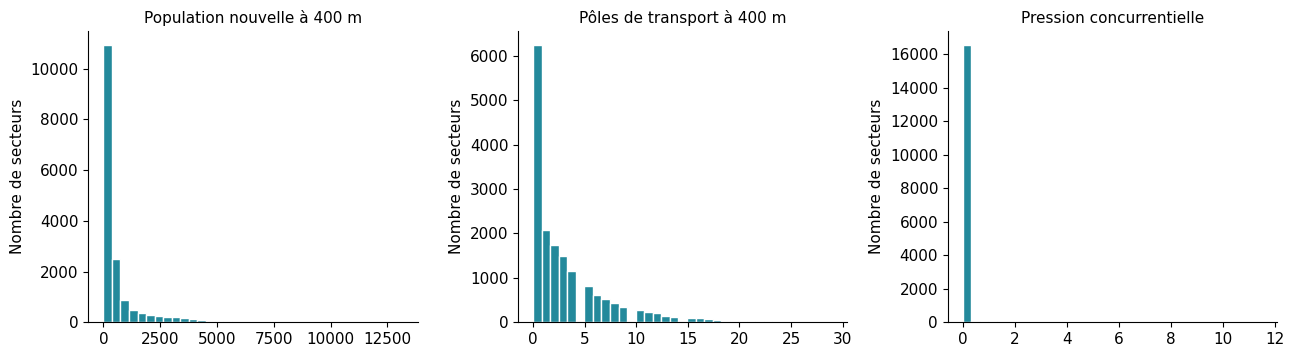

In [3]:
candidats, population, couverture, poles = build_features(pop, sharing, stops_raw, CONFIG)
print(f"{len(candidats):,} candidats après exclusion des points à moins de 800 m de Citiz")
print(f"{len(poles):,} pôles d'arrêts après rapprochement spatial")
display(candidats[['commune','population_nouvelle','arrets_400m',
                   'stations_concurrentes_400m','vehicules_concurrents_400m','distance_citiz_m']].head())
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
for ax, col, title in zip(axes, ['population_nouvelle','arrets_400m','pression_concurrentielle'],
                         ['Population nouvelle à 400 m','Pôles de transport à 400 m','Pression concurrentielle']):
    ax.hist(candidats[col], bins=35, color='#23899b', edgecolor='white')
    ax.set_title(title, fontsize=11); ax.set_ylabel('Nombre de secteurs')
fig.tight_layout(); plt.show()

## 4. Entraîner le modèle de machine learning
**KMeans** apprend des groupes de secteurs aux caractéristiques proches. Les variables sont transformées par `log1p`, puis standardisées pour éviter qu’une population en milliers écrase un nombre d’arrêts en dizaines.

Le nombre de groupes est choisi entre 2 et 6 avec le score de silhouette. C’est une mesure de séparation des groupes, **pas une précision de prédiction de demande**. Les profils aident à expliquer le diagnostic ; leur numéro ne détermine pas le rang d’investissement.

K retenu : 3 · silhouette : 0.478


,population_nouvelle,arrets_400m,pression_concurrentielle
profil_ml,,,
0,573.5,5.0,0.0
1,74.0,0.0,0.0
2,4033.0,13.0,1.2


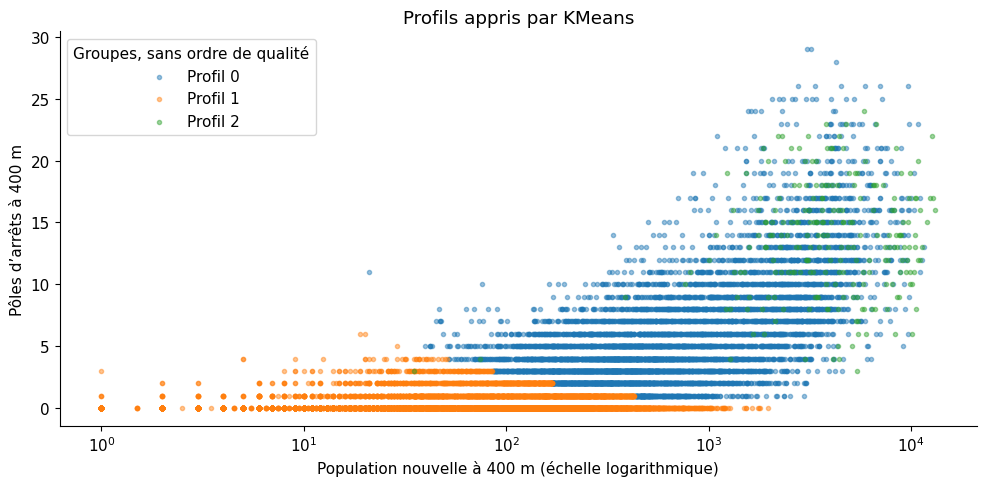

In [4]:
candidats, metriques = segment(candidats, ROOT/'results')
print(f"K retenu : {metriques['k']} · silhouette : {metriques['silhouette']:.3f}")
profils = candidats.groupby('profil_ml')[['population_nouvelle','arrets_400m','pression_concurrentielle']].median().round(1)
display(profils)
fig, ax = plt.subplots(figsize=(10, 5))
for group, d in candidats.groupby('profil_ml'):
    ax.scatter(d.population_nouvelle, d.arrets_400m, s=9, alpha=.45, label=f'Profil {group}')
ax.set_xscale('symlog', linthresh=1)
ax.set_xlabel('Population nouvelle à 400 m (échelle logarithmique)'); ax.set_ylabel('Pôles d’arrêts à 400 m')
ax.set_title('Profils appris par KMeans'); ax.legend(title='Groupes, sans ordre de qualité')
fig.tight_layout(); plt.show()

## 5. Classer puis sélectionner sous budget
Le score individuel combine **60 % population + 25 % transports + 15 % faible concurrence**. Population et transports sont normalisés après logarithme. Le score n’est ni une probabilité ni un chiffre d’affaires.

La sélection gloutonne utilise ensuite le gain marginal de population par euro, pondéré par le score. Elle applique le quota communal et l’espacement. Il ne s’agit pas d’une preuve d’optimalité globale.

Les coûts identiques du scénario servent à limiter le nombre d’ouvertures. Pour comparer les coûts des sites, il faudra des devis propres à chaque lieu.

Budget mobilisé : 500,000 € (hypothèse année 1)
Population supplémentaire sans double compte : 54,706


,rang,commune,arret_proche,lat,lon,score,population_400m,habitants_supplementaires,arrets_400m,stations_concurrentes_400m,vehicules_concurrents_400m,cout_eur
0,1,Nice,Estienne d'Orves,43.70142,7.25323,96.5,9812.0,9812.0,23,0,0,50000
1,2,Nice,Bavastro,43.70048,7.28548,95.5,10291.0,10291.0,19,0,0,50000
2,3,Beausoleil,Gaumattes,43.73998,7.41746,92.5,4522.0,4522.0,26,0,0,50000
3,4,Grasse,CROUET,43.65598,6.92370,91.9,4726.0,4726.0,23,0,0,50000
4,5,Cagnes-sur-Mer,Bourdet,43.66434,7.15102,91.1,5802.0,5802.0,17,0,0,50000
5,6,Cannes,Les Orangers,43.55194,7.00827,91.0,3186.0,3186.0,29,0,0,50000
6,7,Beausoleil,Boulevard de la Turbie,43.74564,7.42712,90.8,3051.0,3051.0,29,0,0,50000
7,8,Le Cannet,Paul Doumer,43.56665,7.01740,90.2,5388.0,5388.0,16,0,0,50000
8,9,Roquebrune-Cap-Martin,Carnolès Marché,43.76508,7.48329,89.7,4426.0,4426.0,18,0,0,50000
9,10,Cannes,Bd Strasbourg Turckheim,43.55432,7.02792,89.7,3502.0,3502.0,22,0,0,50000


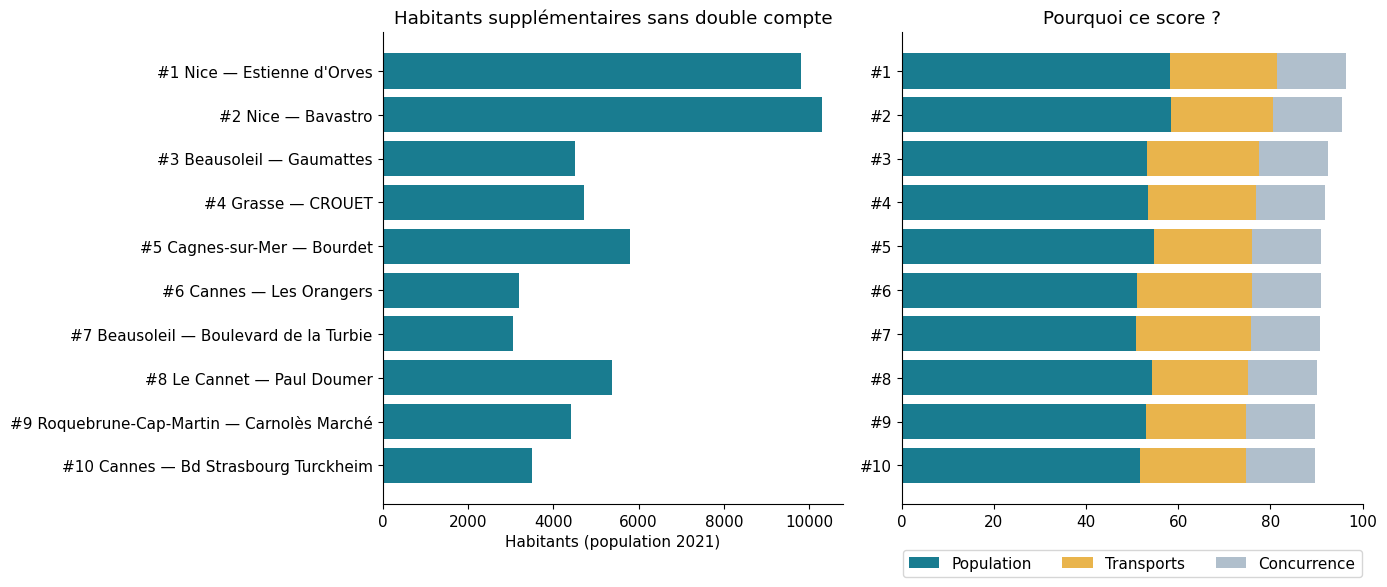

In [5]:
top10 = select(candidats, population, couverture, CONFIG)
assert len(top10) > 0, "Aucun emplacement finançable avec les paramètres choisis"
colonnes = ['rang','commune','arret_proche','lat','lon','score','population_400m',
            'habitants_supplementaires','arrets_400m','stations_concurrentes_400m',
            'vehicules_concurrents_400m','cout_eur']
display(top10[colonnes].round({'score':1,'lat':5,'lon':5,'population_400m':0,'habitants_supplementaires':0}))
print(f"Budget mobilisé : {top10.cout_eur.sum():,.0f} € (hypothèse année 1)")
print(f"Population supplémentaire sans double compte : {top10.habitants_supplementaires.sum():,.0f}")
top10.to_csv(ROOT/'results/top10.csv',index=False)
candidats.to_csv(ROOT/'results/candidats.csv',index=False)
(ROOT/'results/config.json').write_text(json.dumps(CONFIG,indent=2))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
labels = top10.apply(lambda r: f"#{int(r.rang)} {r.commune} — {r.arret_proche}", axis=1)
axes[0].barh(labels,top10.habitants_supplementaires,color='#197c90'); axes[0].invert_yaxis()
axes[0].set_title('Habitants supplémentaires sans double compte'); axes[0].set_xlabel('Habitants (population 2021)')
w=np.array(CONFIG['weights'])/sum(CONFIG['weights']);left=np.zeros(len(top10))
for col,weight,color,label in zip(['s_population','s_transport','s_concurrence'],w,
                                ['#197c90','#e9b44c','#b0bfcc'],['Population','Transports','Concurrence']):
    part=top10[col].to_numpy()*weight*100
    axes[1].barh(np.arange(len(top10)),part,left=left,color=color,label=label);left+=part
axes[1].set_yticks(np.arange(len(top10)),[f'#{i}' for i in top10.rang]);axes[1].invert_yaxis()
axes[1].set_xlim(0,100);axes[1].set_title('Pourquoi ce score ?');axes[1].legend(loc='upper center',bbox_to_anchor=(.5,-.08),ncol=3)
fig.tight_layout();fig.savefig(ROOT/'results/top10_graphiques.png',dpi=150,bbox_inches='tight');plt.show()

## 6. Carte des secteurs retenus
Les cercles représentent 400 m à vol d’oiseau. Cliquer sur un point affiche sa justification. Les coordonnées sont celles du **centre d’un carreau**, et le nom d’arrêt est uniquement un repère proche.

In [6]:
carte = export_map(top10,candidats,sharing,poles,ROOT/'results/carte_top10.html')
display(carte)

## 7. Le top 10 dépend-il des poids ?
On conserve la même base et les mêmes contraintes, puis on change les priorités. Le nombre de secteurs qui restent à moins de 400 m d’un secteur initial donne une lecture plus utile qu’un simple changement de carreau de 200 m. Ce diagnostic ne remplace pas une validation terrain.

,scénario,habitants_supplémentaires,secteurs_proches_du_top_initial,nombre,communes
0,Équilibre,54706,10,10,"Nice, Beausoleil, Grasse, Cagnes-sur-Mer, Cann..."
1,Population,62664,7,10,"Nice, Cagnes-sur-Mer, Beausoleil, Grasse, Le C..."
2,Intermodalité,50120,7,10,"Nice, Beausoleil, Cannes, Grasse, Cagnes-sur-M..."
3,Concurrence,54706,10,10,"Nice, Beausoleil, Grasse, Cagnes-sur-Mer, Cann..."


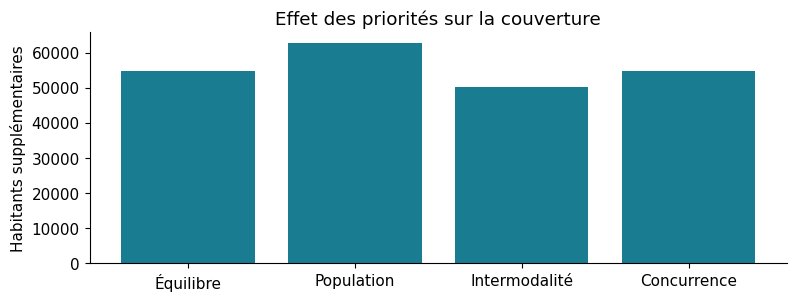

In [7]:
scenarios = {'Équilibre':[.60,.25,.15], 'Population':[.75,.15,.10],
             'Intermodalité':[.45,.40,.15], 'Concurrence':[.50,.20,.30]}
lignes = []
for nom, poids in scenarios.items():
    d=candidats.copy();w=np.array(poids)/sum(poids)
    d['score']=100*(w[0]*d.s_population+w[1]*d.s_transport+w[2]*d.s_concurrence)
    t=select(d,population,couverture,{**CONFIG,'weights':poids})
    dist,_=nearest(t,top10)
    lignes.append({'scénario':nom,'habitants_supplémentaires':round(t.habitants_supplementaires.sum()),
                   'secteurs_proches_du_top_initial':int((dist<=400).sum()),'nombre':len(t),
                   'communes':', '.join(t.commune.drop_duplicates())})
sensibilite=pd.DataFrame(lignes)
display(sensibilite)
sensibilite.to_csv(ROOT/'results/sensibilite.csv',index=False)
fig,ax=plt.subplots(figsize=(9,3))
ax.bar(sensibilite['scénario'],sensibilite.habitants_supplémentaires,color='#197c90')
ax.set_ylabel('Habitants supplémentaires');ax.set_title('Effet des priorités sur la couverture');plt.show()

## 8. Contrôles de cohérence
Vérifier le budget, le quota, l’exclusion Citiz, la séparation spatiale et surtout l’absence de double compte des habitants. Ces contrôles valident les calculs, pas la réussite commerciale.

In [8]:
assert len(top10)<=CONFIG['top_n']
assert top10.cout_eur.sum()<=CONFIG['budget_eur']
assert top10.groupby('commune').size().max()<=CONFIG['max_per_commune']
assert top10.distance_citiz_m.min()>=CONFIG['exclude_citiz_m']
prox=neighbors(top10,top10,CONFIG['separation_m']-0.01)
assert all(len(x)==1 for x in prox)
ids=set(top10.id)
indices=[i for i,x in enumerate(candidats.id) if x in ids]
union=np.unique(np.concatenate([couverture[i] for i in indices]))
new=union[~population.iloc[union].already_citiz.to_numpy()]
assert np.isclose(population.iloc[new].population.sum(),top10.habitants_supplementaires.sum())
print('Contrôles validés : budget, quota, distance Citiz, espacement, gain marginal.')
print('Part de population imputée autour des secteurs :')
display(top10[['rang','commune','part_population_imputee']].assign(part_population_imputee=lambda d:(100*d.part_population_imputee).round(1)))

Contrôles validés : budget, quota, distance Citiz, espacement, gain marginal.
Part de population imputée autour des secteurs :


,rang,commune,part_population_imputee
0,1,Nice,0.0
1,2,Nice,0.0
2,3,Beausoleil,0.0
3,4,Grasse,0.0
4,5,Cagnes-sur-Mer,0.0
5,6,Cannes,0.0
6,7,Beausoleil,0.5
7,8,Le Cannet,0.0
8,9,Roquebrune-Cap-Martin,0.0
9,10,Cannes,0.0


## 9. Entraîner une Random Forest sur des réservations réelles
Les API actuelles ne contiennent pas la cible d’apprentissage. **Aucune fréquentation n’a été inventée.** Ajouter `data/historique_usage.csv` selon le schéma du README active cette cellule.

La validation sépare les communes et compare la Random Forest à la moyenne des stations d’entraînement. Il faut des caractéristiques connues avant la période observée, une observation agrégée par station et un contrôle des différences de marché. Un meilleur résultat que la référence ne suffit pas à garantir le transfert géographique.

In [9]:
historique=ROOT/'data/historique_usage.csv'
if historique.exists():
    from supervised import train_usage, FEATURES
    modele, evaluation = train_usage(historique,ROOT/'results')
    display(evaluation)
    predictions=top10[['rang','commune','arret_proche']].copy()
    predictions['reservations_par_voiture_mois']=modele.predict(top10[FEATURES])
    display(predictions)
    print('Prévisions exploratoires, à auditer avant de les intégrer à la décision.')
else:
    print('Pas d’historique d’usage fourni : modèle supervisé non entraîné. Le top 10 est un classement multicritère.')

Pas d’historique d’usage fourni : modèle supervisé non entraîné. Le top 10 est un classement multicritère.


## 10. Recollecter les données et aller plus loin
Les cellules suivantes sont désactivées par défaut pour ne pas retélécharger de gros fichiers. Lancer la collecte puis reconstruire les variables après tout rafraîchissement.

Les étapes avant une véritable implantation : compléter l’inventaire concurrentiel, filtrer les calendriers GTFS et intégrer les fréquences, calculer les trajets piétons sur OSM, ajouter tourisme/emplois/motorisation, obtenir les coûts de stationnement et les usages Citiz, puis visiter les sites.

Les projections Omphale départementales du PDF ne sont pas artificiellement réparties sur des carreaux : elles ne donnent pas directement une croissance de quartier. Le Var et Monaco sont hors du classement actuel.

In [10]:
# À exécuter volontairement dans un terminal :
# python collect.py --refresh
# python collect.py --population
# Puis relancer le notebook depuis la section 2.
# Sources détaillées et limites : SOURCES.md et README.md.